**Student Name:** Temuulen Batsaikhan

**Student Number:** 8252026

**Lecturer:** Taufique Ahmed

**Module:** Data Visualisation and Communication

**Assessment:** CA1 — AI Employment Data Visualisation

**College:** CCT College Dublin

**Dataset:** US Bureau of Labor Statistics May 2023

**GitHub:** https://github.com/Temuulen-BCS/Data-Visualisation

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TYPE",
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP",
        "A_MEAN"
    ]
)

print(df.shape)
df.head()

(413327, 8)


,AREA_TITLE,AREA_TYPE,NAICS,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEAN
0,U.S.,1,000000,00-0000,All Occupations,total,151853870,65470
1,U.S.,1,000000,11-0000,Management Occupations,major,10495770,137750
2,U.S.,1,000000,11-1000,Top Executives,minor,3751510,136100
3,U.S.,1,000000,11-1010,Chief Executives,broad,211230,258900
4,U.S.,1,000000,11-1011,Chief Executives,detailed,211230,258900


In [18]:
occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists",
    "Information Security Analysts",
    "Computer Programmers"]

df["NAICS"] = pd.to_numeric(df["NAICS"], errors="coerce")
df["TOT_EMP"] = pd.to_numeric(df["TOT_EMP"], errors="coerce")
df["A_MEAN"] = pd.to_numeric(df["A_MEAN"], errors="coerce")

filtered_data = df[
    (df["NAICS"] == 0) &
    (df["O_GROUP"] == "detailed") &
    (df["OCC_TITLE"].isin(occupations))].copy()

national_data = filtered_data[
    filtered_data["AREA_TITLE"] == "U.S."].copy()

state_data = filtered_data[
    filtered_data["AREA_TYPE"] == 2].copy()

print("National records:", len(national_data))
print("State records:", len(state_data))
national_data[["OCC_TITLE", "TOT_EMP", "A_MEAN"]]

National records: 5
State records: 246


,OCC_TITLE,TOT_EMP,A_MEAN
136,Information Security Analysts,175350.0,124740.0
138,Computer and Information Research Scientists,35210.0,157160.0
148,Computer Programmers,120370.0,107750.0
149,Software Developers,1656880.0,138110.0
165,Data Scientists,192710.0,119040.0


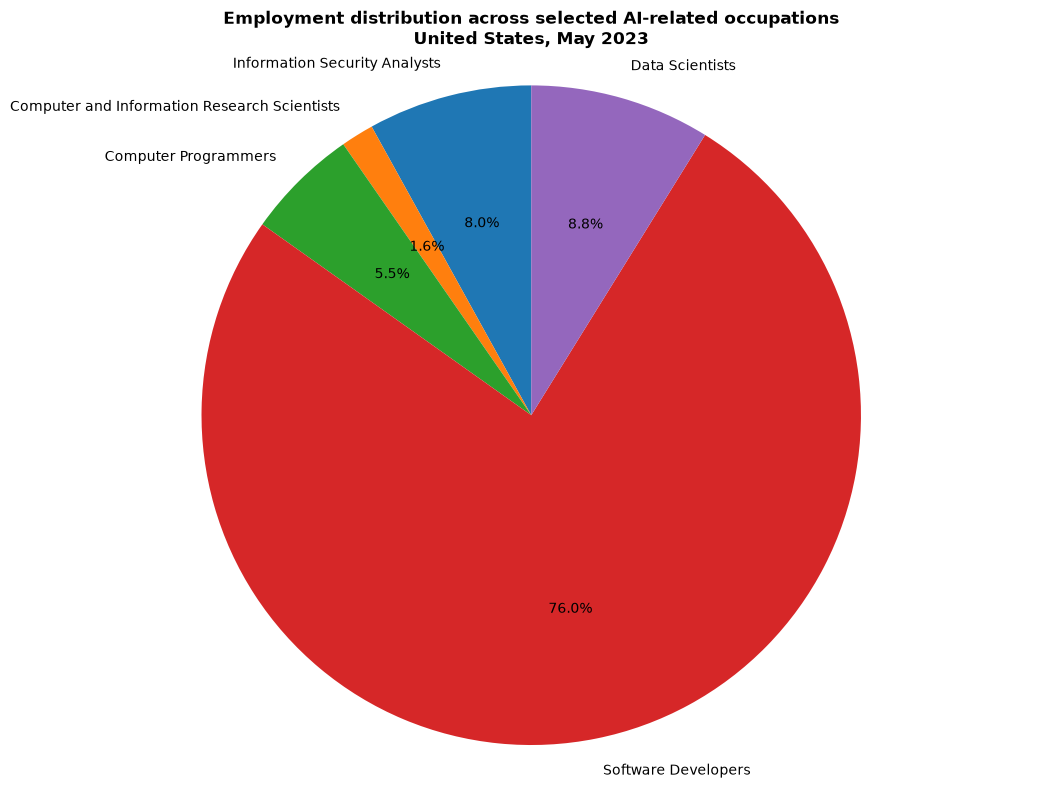

In [20]:
pie_data = national_data.dropna(subset=["TOT_EMP"])

plt.figure(figsize=(11, 8))
plt.pie(
    pie_data["TOT_EMP"],
    labels=pie_data["OCC_TITLE"],
    autopct="%1.1f%%",
    startangle=90)

plt.title(
    "Employment distribution across selected AI-related occupations\n"
    "United States, May 2023",
    fontweight="bold")

plt.axis("equal")
plt.tight_layout()
plt.show()

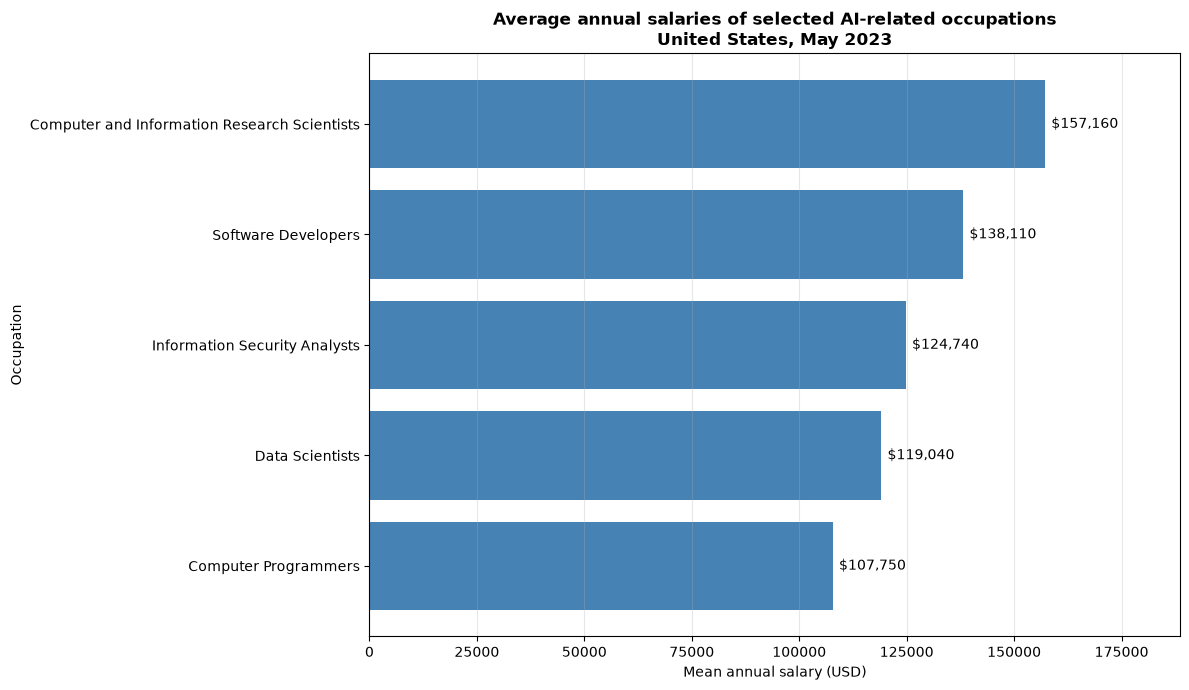

In [21]:
salary_data = national_data.sort_values("A_MEAN")
plt.figure(figsize=(12, 7))
plt.barh(
    salary_data["OCC_TITLE"],
    salary_data["A_MEAN"],
    color="steelblue")

for i, salary in enumerate(salary_data["A_MEAN"]):
    plt.text(
        salary + 1500,
        i,
        f"${salary:,.0f}",
        va="center")

plt.title(
    "Average annual salaries of selected AI-related occupations\n"
    "United States, May 2023",
    fontweight="bold")

plt.xlabel("Mean annual salary (USD)")
plt.ylabel("Occupation")
plt.xlim(0, salary_data["A_MEAN"].max() * 1.2)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

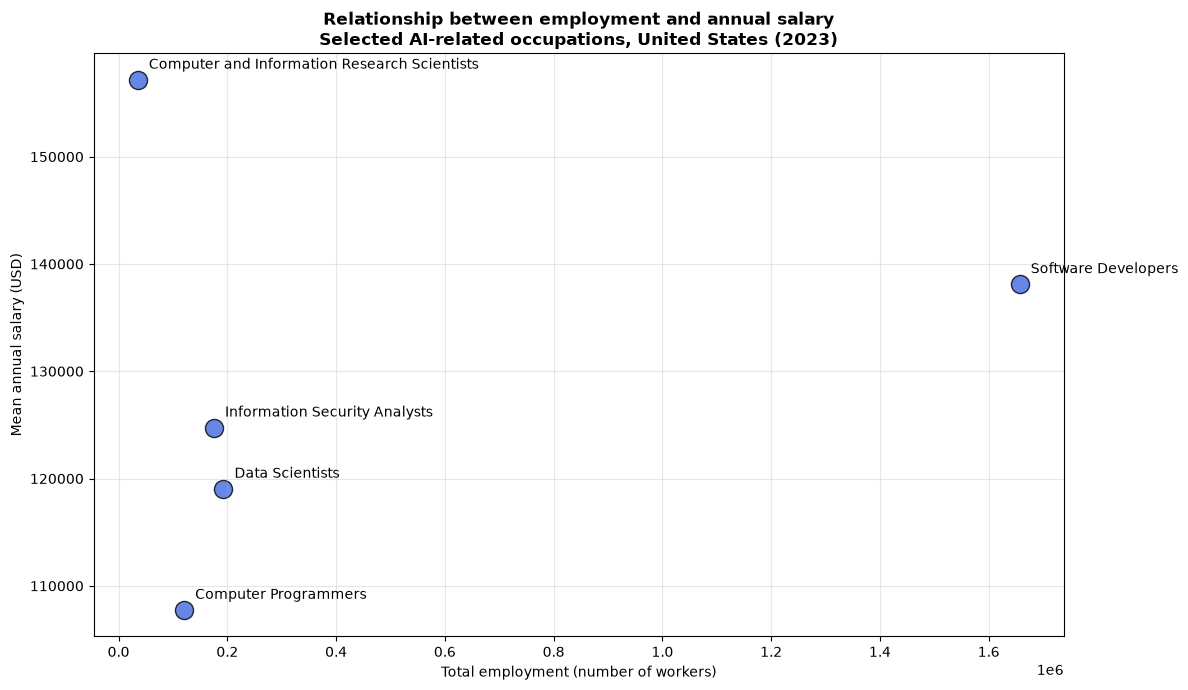

In [22]:
scatter_data = national_data.dropna(
    subset=["TOT_EMP", "A_MEAN"])

plt.figure(figsize=(12, 7))

plt.scatter(
    scatter_data["TOT_EMP"],
    scatter_data["A_MEAN"],
    s=170,
    color="royalblue",
    edgecolors="black",
    alpha=0.8)

for _, row in scatter_data.iterrows():
    plt.annotate(
        row["OCC_TITLE"],
        (row["TOT_EMP"], row["A_MEAN"]),
        xytext=(8, 8),
        textcoords="offset points")

plt.title(
    "Relationship between employment and annual salary\n"
    "Selected AI-related occupations, United States (2023)",
    fontweight="bold")

plt.xlabel("Total employment (number of workers)")
plt.ylabel("Mean annual salary (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

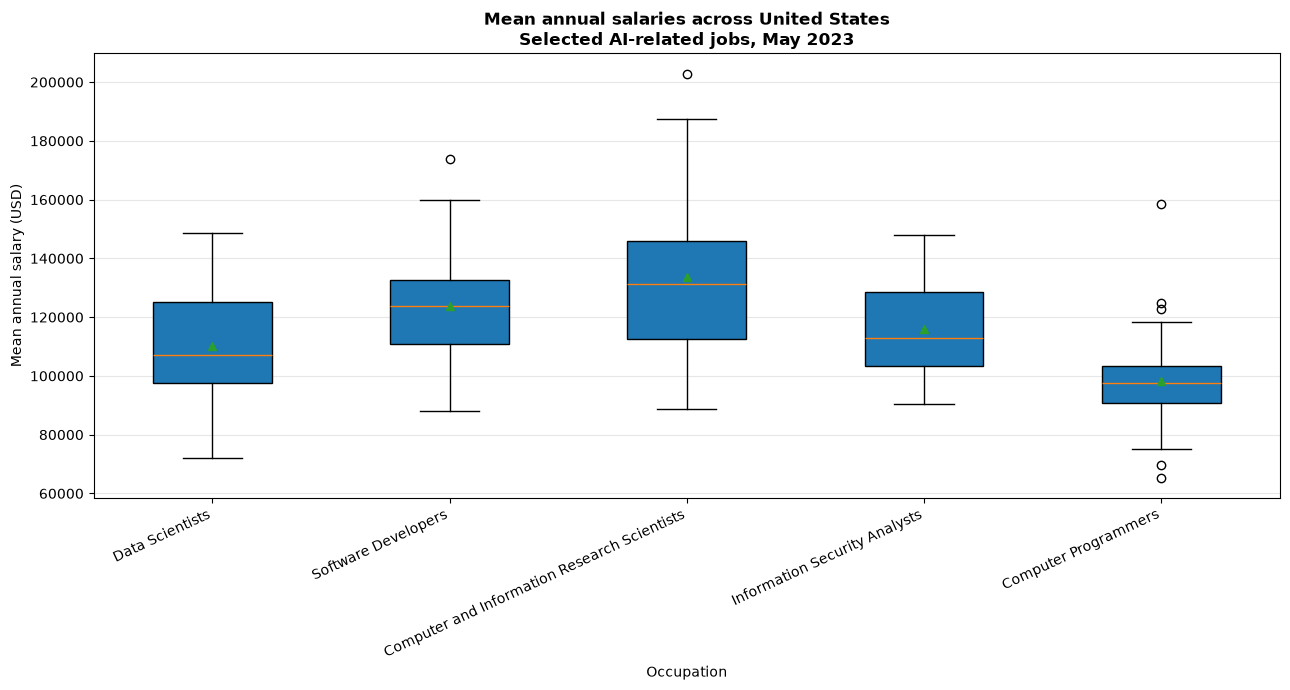

In [26]:
box_data = state_data.dropna(subset=["A_MEAN"])

salary_groups = [
    box_data.loc[
        box_data["OCC_TITLE"] == occupation,
        "A_MEAN" ].values for occupation in occupations]

plt.figure(figsize=(13, 7))
plt.boxplot(
    salary_groups,
    tick_labels=occupations,
    patch_artist=True,
    showmeans=True)

plt.title(
    "Mean annual salaries across United States\n"
    "Selected AI-related jobs, May 2023",
    fontweight="bold")

plt.xlabel("Occupation")
plt.ylabel("Mean annual salary (USD)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

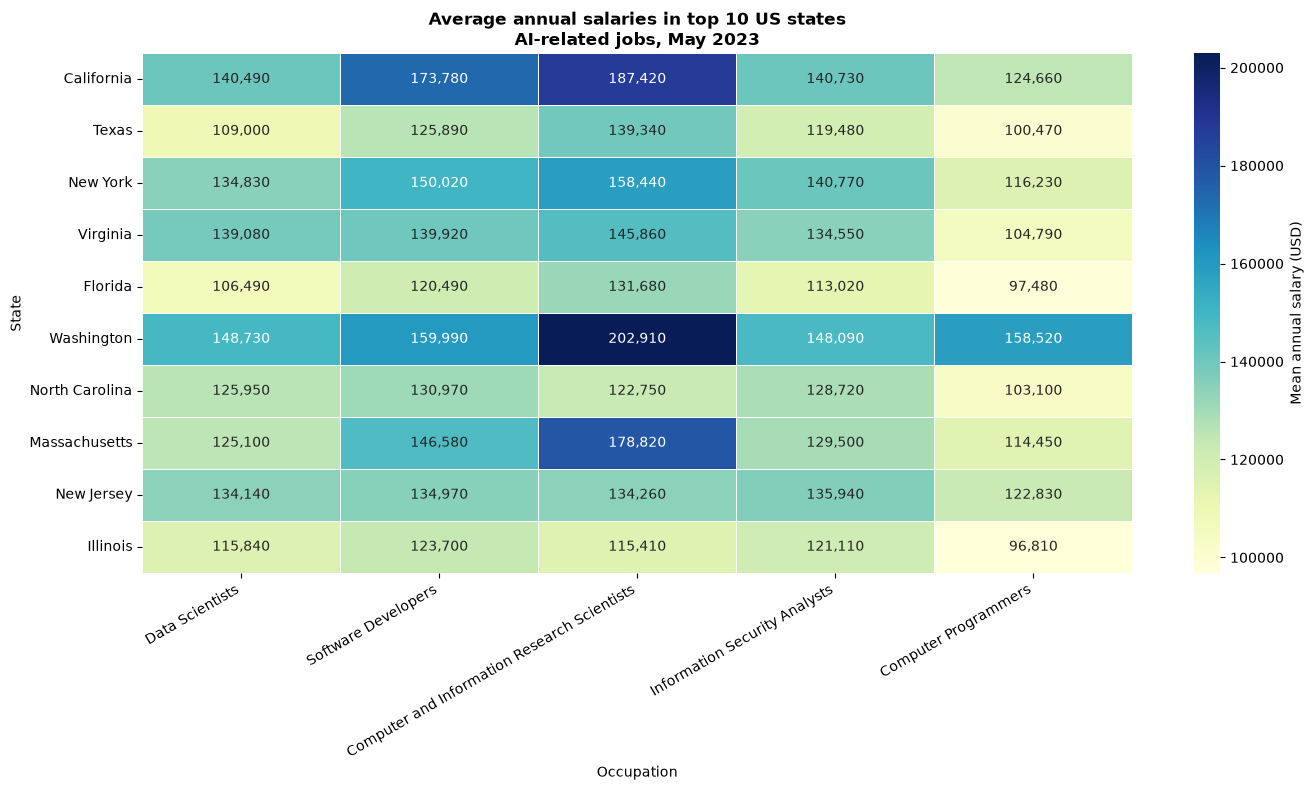

In [27]:
top_states = (
    state_data.groupby("AREA_TITLE")["TOT_EMP"]
    .sum(min_count=1)
    .nlargest(10)
    .index)

heatmap_data = state_data[
    state_data["AREA_TITLE"].isin(top_states)].pivot_table(
    index="AREA_TITLE",
    columns="OCC_TITLE",
    values="A_MEAN",
    aggfunc="first")

heatmap_data = heatmap_data.reindex(
    index=top_states,
    columns=occupations)

plt.figure(figsize=(14, 8))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Mean annual salary (USD)"})

plt.title(
    "Average annual salaries in top 10 US states\n"
    "AI-related jobs, May 2023",
    fontweight="bold")

plt.xlabel("Occupation")
plt.ylabel("State")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
print("National records:", len(national_data))
print("State records:", len(state_data))

print("\nMissing values:")
print(filtered_data[["TOT_EMP", "A_MEAN"]].isna().sum())

print("\nDuplicate national occupations:")
print(national_data.duplicated(subset=["OCC_CODE"]).sum())

print("\nDuplicate state occupations:")
print(
    state_data.duplicated(subset=["AREA_TITLE", "OCC_CODE"]).sum())

National records: 5
State records: 246

Missing values:
TOT_EMP    25
A_MEAN     17
dtype: int64

Duplicate national occupations:
0

Duplicate state occupations:
0
